# D1c. 학습량 곡선 — 60만 문장 (Colab A100 권장)

**왜**: 20만 → 30만에서 dev F1이 1.55점 올라 팀 기준을 30만으로 바꿨다(`reports/결정기록.md` 결정 1 보충). 곡선이 아직 평평해지지 않았으므로 60만에서도 0.7점 이상 오르는지 본다.

**조건**: 다른 D1 실험과 똑같다(klue/roberta-base, 3에폭, 학습률 5e-5, 배치 16, 최대 길이 512, 시드 42, dev·test는 split_v1). 60만 세트는 30만 세트 + 새 문장 30만이라 포함 관계가 유지된다(`data/exp_sets/stats_lc_600000.json`).

**예상 시간**: A100 약 1시간 40분(30만 A100 실측 46.8분 × 2 + 데이터 변환). L4는 약 5시간이라 비추천. 서버 조각(MIG 1g)은 약 5시간.
**런타임**: A100 + **높은 RAM** 권장(60만 문장 변환). "모두 실행"하면 끝난 뒤 결과 저장을 확인하고 런타임을 자동 반납한다.

**주의**: 서버에서도 같은 이름(D1_lc_600000)이 돌고 있으면 둘 중 하나만 쓴다. 먼저 끝난 쪽 결과를 쓰고 다른 쪽은 멈춘다.


## 0. 공통 준비 (모든 노트북 같음)
Colab → 런타임 → 런타임 유형 변경 → GPU(T4 이상). 구글 드라이브를 연결하면 이 PC의 프로젝트 폴더가 `/content/drive/Othercomputers/내 PC/...` 아래에 보인다. 경로가 다르면 왼쪽 파일 탭에서 찾아 `PROJECT` 만 고친다.

공용 코드 `src/ner_lib.py`(학습)와 `src/evaluate.py`(팀 공용 채점기)를 불러온다. 정렬·복원·채점 규칙이 모든 노트북에서 같아야 비교가 공정하기 때문이다.

**저장되는 것**: 실험마다 `reports/results/{실험}.json`(에폭별 dev 점수 포함), `preds/`(예측), `scores/`(채점), `errors/`(오답), 그리고 `runs.jsonl`(실행 기록 한 줄). 그림은 R0 노트북이 이 파일들로 그린다.
**끊겼을 때**: 같은 셀을 다시 실행하면 끝난 실험은 건너뛰고, 진행 중이던 실험은 마지막 에폭 체크포인트부터 이어서 학습한다.

**최종 가중치(10/23부터 항상 저장)**: 학습이 끝나면 예측·채점보다 먼저 `내 드라이브/ner_models/{실험}/` 에 가중치(model.safetensors 또는 crf_model_state.pt)와 토크나이저를 저장하고, 다시 읽어 학습된 값과 같은지 확인한다. 확인에 실패하면 체크포인트를 지우지 않고 멈춘다. 런타임 반납 전에도 한 번 더 확인한다.

In [2]:
!pip -q install -U transformers datasets accelerate pytorch-crf kiwipiepy
import sys, os, json, torch
from google.colab import drive
drive.mount("/content/drive")
PROJECT = "/content/drive/Othercomputers/내 PC/NLP/프로젝트1/공통2_개체명인식_NER"
sys.path.insert(0, f"{PROJECT}/src")
import importlib, ner_lib; importlib.reload(ner_lib)
MODELS = "/content/drive/MyDrive/ner_models"   # 최종 가중치(실험마다 폴더). 학습 직후 저장하고 다시 읽어 확인한다. 지우지 말 것
ner_lib.DEFAULTS.update(model_dir=MODELS)
from ner_lib import run_experiment, load_results, results_table, upper_bound, load_jsonl, prepare_aihub_model
SPLIT   = f"{PROJECT}/data/split_v1"          # dev 1만 / test 1만 (모든 버전 공통)
TRAIN   = f"{PROJECT}/data/split_v3/train.jsonl"   # 팀 기준 학습 데이터: 30만 (2026-10-22 결정)
SUFFIX  = "_300k"                              # 30만으로 학습한 실험 이름 꼬리표
RESULTS = f"{PROJECT}/reports/results"        # 결과 json이 모이는 곳 (팀원 모두 같은 폴더)
CKPT    = "/content/drive/MyDrive/ner_ckpt"    # 에폭 체크포인트. 끊겨도 이어서 학습. '내 드라이브'라 PC로 동기화되지 않음
MEMBER  = "sejin_choi"                          # ← 실행한 사람 이름, 영어로 (결과 기록 runs.jsonl에 남음)
ner_lib.DEFAULTS.update(ckpt_dir=CKPT, member=MEMBER)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음")

Mounted at /content/drive
GPU: NVIDIA A100-SXM4-80GB


In [3]:
# 한글 글꼴 (그래프 글자가 네모로 깨지지 않게)
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.pyplot as plt, matplotlib.font_manager as fm, glob as _g
for f in _g.glob("/usr/share/fonts/truetype/nanum/*.ttf"): fm.fontManager.addfont(f)
plt.rc("font", family="NanumGothic"); plt.rc("axes", unicode_minus=False)
FIG = f"{PROJECT}/reports/figures"; os.makedirs(FIG, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150); plt.show(); print("저장:", f"{FIG}/{name}.png")

In [4]:
ner_lib.DEFAULTS["stage"] = "D1_학습량곡선"
EXP = f"{PROJECT}/data/exp_sets"
COMMON = dict(dev=f"{SPLIT}/dev.jsonl", test=f"{SPLIT}/test.jsonl", out_dir=RESULTS, model="klue/roberta-base",
              max_len=512, lr=5e-5, epochs=3, batch=16, seed=42)
RUNS = {"D1_lc_600000": dict(train=f"{EXP}/lc_train_600000.jsonl")}
print("GPU:", torch.cuda.get_device_name(0), "| bf16:", torch.cuda.is_bf16_supported())

GPU: NVIDIA A100-SXM4-80GB | bf16: True


## 1. 시작 전 확인
60만 세트(약 217MB)가 드라이브에 올라왔는지 본다. "없음"이면 PC의 구글 드라이브 동기화가 끝나지 않은 것이므로 잠시 뒤 다시 실행한다.


In [5]:
need = [COMMON["dev"], COMMON["test"]] + [v["train"] for v in RUNS.values()]
for f in need:
    ok = os.path.exists(f); print("있음" if ok else "없음!!", f.replace(PROJECT, "..."), f"{os.path.getsize(f)/1e6:.1f}MB" if ok else "")
assert all(os.path.exists(f) for f in need), "데이터 파일이 아직 드라이브에 없습니다"
n = sum(1 for _ in open(RUNS["D1_lc_600000"]["train"], encoding="utf-8")); print("60만 세트 줄 수:", n); assert n == 600000
for exp in RUNS: print(exp, "끝남(건너뜀)" if os.path.exists(f"{RESULTS}/{exp}.json") else "할 차례")

있음 .../data/split_v1/dev.jsonl 3.6MB
있음 .../data/split_v1/test.jsonl 3.8MB
있음 .../data/exp_sets/lc_train_600000.jsonl 217.1MB
60만 세트 줄 수: 600000
D1_lc_600000 할 차례


## 2. 실행
끊기면 0번 셀부터 다시 실행한다. 끝난 실험은 건너뛰고, 진행 중이던 실험은 '내 드라이브/ner_ckpt' 의 마지막 에폭부터 이어서 학습한다.

In [6]:
for exp, v in RUNS.items():
    run_experiment({**COMMON, **v, "exp": exp})

config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/752k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

...

  [epoch 2] dev F1 0.7515 macro 0.571


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [epoch 3] dev F1 0.7649 macro 0.6036


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[D1_lc_600000] dev F1 0.7649 | test F1 0.7511 | 학습 5788.2s (311.04 문장/s)


## 3. 학습량 곡선에 60만 점 추가
판단 기준(결정기록 1과 같음): 30만 → 60만 dev F1 상승이 **0.7점 미만이면 30만 유지, 이상이면 60만 검토**.


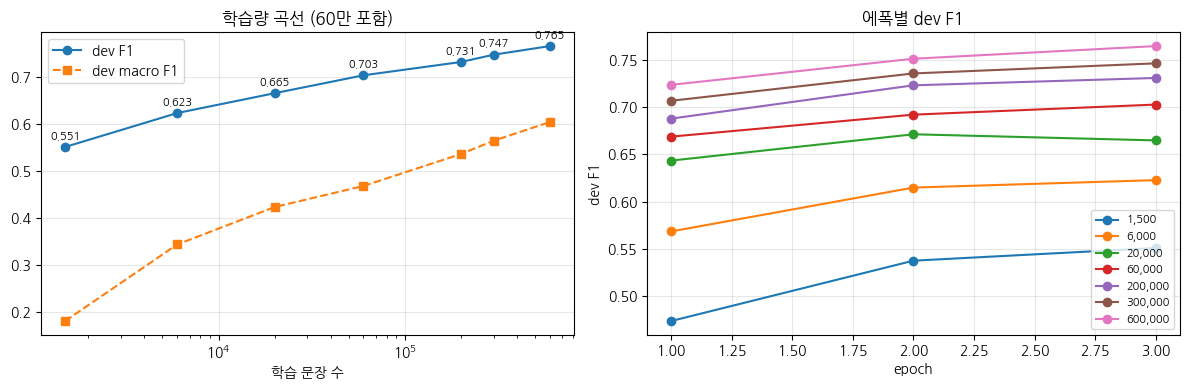

저장: /content/drive/Othercomputers/내 PC/NLP/프로젝트1/공통2_개체명인식_NER/reports/figures/1c_학습량곡선_60만.png
  1,500 →   6,000: dev +7.20점, macro +16.25점, 시간 ×2.7 (NVIDIA A100 80GB PCIe MIG 1g.10gb)
  6,000 →  20,000: dev +4.21점, macro +7.94점, 시간 ×3.0 (NVIDIA A100 80GB PCIe MIG 1g.10gb)
 20,000 →  60,000: dev +3.80점, macro +4.47점, 시간 ×2.9 (NVIDIA A100 80GB PCIe MIG 1g.10gb)
 60,000 → 200,000: dev +2.82점, macro +6.77점, 시간 ×3.3 (NVIDIA A100 80GB PCIe MIG 1g.10gb)
200,000 → 300,000: dev +1.55점, macro +2.83점, 시간 ×0.5 (NVIDIA A100-SXM4-40GB)
300,000 → 600,000: dev +1.83점, macro +3.95점, 시간 ×2.1 (NVIDIA A100-SXM4-80GB)


In [7]:
lc = sorted([r for r in load_results(RESULTS) if r["exp"].startswith("D1_lc_")], key=lambda r: r["n_train"])
n = [r["n_train"] for r in lc]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(n, [r["dev"]["ALL"]["f1"] for r in lc], "o-", label="dev F1"); ax[0].plot(n, [r["dev"]["MACRO_F1"] for r in lc], "s--", label="dev macro F1")
for x, r in zip(n, lc): ax[0].annotate(f"{r['dev']['ALL']['f1']:.3f}", (x, r["dev"]["ALL"]["f1"]), fontsize=8, xytext=(0, 6), textcoords="offset points", ha="center")
ax[0].set_xscale("log"); ax[0].set_xlabel("학습 문장 수"); ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_title("학습량 곡선 (60만 포함)")
for r in lc: ax[1].plot([h["epoch"] for h in r["history"]], [h["dev_f1"] for h in r["history"]], "o-", label=f"{r['n_train']:,}")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("dev F1"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3); ax[1].set_title("에폭별 dev F1")
savefig("1c_학습량곡선_60만")
for a, b in zip(lc, lc[1:]):
    print(f"{a['n_train']:>7,} → {b['n_train']:>7,}: dev +{(b['dev']['ALL']['f1']-a['dev']['ALL']['f1'])*100:.2f}점, "
          f"macro +{(b['dev']['MACRO_F1']-a['dev']['MACRO_F1'])*100:.2f}점, 시간 ×{b['train_sec']/max(a['train_sec'],1):.1f} ({b['gpu']})")

## 4. 저장 확인 후 런타임 반납
결과 파일이 모두 드라이브에 있으면 저장을 마무리하고 런타임을 반납한다(컴퓨팅 단위 절약). 하나라도 없으면 멈춘다.

In [8]:
ner_lib.verify_saved_models()   # 이번에 다룬 실험의 최종 가중치가 하나라도 없으면 여기서 멈추고 반납하지 않음
print("가중치 위치:", MODELS)
missing = []
for exp in RUNS:
    for f in (f"{RESULTS}/{exp}.json", f"{RESULTS}/scores/{exp}_dev.json", f"{RESULTS}/scores/{exp}_test.json",
              f"{RESULTS}/preds/{exp}_dev.jsonl", f"{RESULTS}/preds/{exp}_test.jsonl",
              f"{RESULTS}/errors/{exp}_dev.jsonl", f"{RESULTS}/errors/{exp}_test.jsonl"):
        if not os.path.exists(f): missing.append(f.replace(RESULTS, "results"))
if missing:
    print("저장 안 된 파일이 있어 반납하지 않습니다:", missing[:10])
else:
    print("결과 파일 모두 저장됨. 드라이브 저장을 마무리하고 런타임을 반납합니다.")
    drive.flush_and_unmount()
    from google.colab import runtime
    runtime.unassign()

결과 파일 모두 저장됨. 드라이브 저장을 마무리하고 런타임을 반납합니다.
